In [1]:
!pip -q install kagglehub

In [2]:
import kagglehub
import os
import shutil
from pathlib import Path


dataset_path = kagglehub.dataset_download(
    "andrewmvd/drive-digital-retinal-images-for-vessel-extraction"
)

print("Dataset downloaded to:", dataset_path)


project_dir = Path("/content/retinal-vessel-segmentation-unet")
data_dir = project_dir / "data" / "DRIVE"


if data_dir.exists():
    shutil.rmtree(data_dir)


data_dir.parent.mkdir(parents=True, exist_ok=True)
shutil.copytree(dataset_path, data_dir)

print("Copied to:", data_dir)

100%|██████████| 28.0M/28.0M [00:00<00:00, 35.5MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/andrewmvd/drive-digital-retinal-images-for-vessel-extraction/versions/1
Copied to: /content/retinal-vessel-segmentation-unet/data/DRIVE


In [3]:
import os
from pathlib import Path

project_dir = Path("/content/retinal-vessel-segmentation-unet")
data_dir = project_dir / "data" / "DRIVE"

for root, dirs, files in os.walk(data_dir):
    level = root.replace(str(data_dir), "").count(os.sep)
    indent = " " * 4 * level
    print(f"{indent}{os.path.basename(root)}/")

    subindent = " " * 4 * (level + 1)
    for file in files[:8]:
        print(f"{subindent}{file}")

DRIVE/
    DRIVE/
        training/
            images/
                37_training.tif
                26_training.tif
                28_training.tif
                38_training.tif
                40_training.tif
                23_training.tif
                22_training.tif
                36_training.tif
            mask/
                29_training_mask.gif
                26_training_mask.gif
                22_training_mask.gif
                23_training_mask.gif
                25_training_mask.gif
                24_training_mask.gif
                34_training_mask.gif
                32_training_mask.gif
            1st_manual/
                23_manual1.gif
                29_manual1.gif
                21_manual1.gif
                36_manual1.gif
                38_manual1.gif
                35_manual1.gif
                39_manual1.gif
                40_manual1.gif
        test/
            images/
                08_test.tif
                18_test.tif
            

Training image directory: /content/retinal-vessel-segmentation-unet/data/DRIVE/DRIVE/training/images
Training mask directory: /content/retinal-vessel-segmentation-unet/data/DRIVE/DRIVE/training/1st_manual
Number of training images: 20
Number of training masks: 20


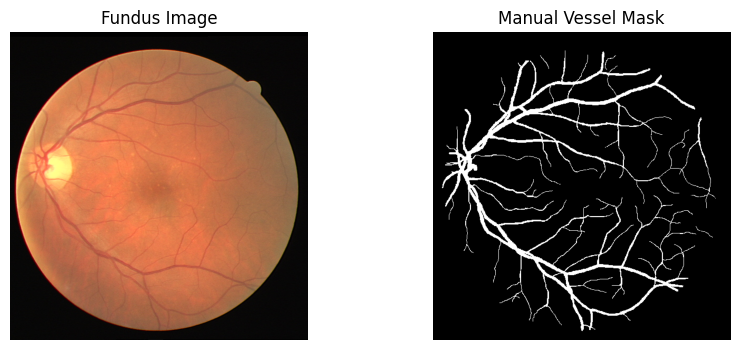

In [4]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt


project_dir = Path("/content/retinal-vessel-segmentation-unet")
data_dir = project_dir / "data" / "DRIVE"


train_image_dir = list(data_dir.rglob("training/images"))[0]
train_mask_dir = list(data_dir.rglob("training/1st_manual"))[0]

print("Training image directory:", train_image_dir)
print("Training mask directory:", train_mask_dir)


image_paths = sorted(list(train_image_dir.glob("*.tif")))
mask_paths = sorted(list(train_mask_dir.glob("*.gif")))

print("Number of training images:", len(image_paths))
print("Number of training masks:", len(mask_paths))


img = Image.open(image_paths[0])
mask = Image.open(mask_paths[0])

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Fundus Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("Manual Vessel Mask")
plt.axis("off")

plt.show()

In [5]:
from pathlib import Path
import random

project_dir = Path("/content/retinal-vessel-segmentation-unet")
data_dir = project_dir / "data" / "DRIVE"

train_image_dir = list(data_dir.rglob("training/images"))[0]
train_mask_dir = list(data_dir.rglob("training/1st_manual"))[0]

train_images = sorted(list(train_image_dir.glob("*.tif")))
train_masks = sorted(list(train_mask_dir.glob("*.gif")))

def get_image_id(path):
    return path.name.split("_")[0]

mask_dict = {get_image_id(mask_path): mask_path for mask_path in train_masks}

pairs = []

for image_path in train_images:
    image_id = get_image_id(image_path)

    if image_id in mask_dict:
        pairs.append((image_path, mask_dict[image_id]))

print("Total paired samples:", len(pairs))

for image_path, mask_path in pairs[:5]:
    print(image_path.name, " --> ", mask_path.name)

random.seed(42)
random.shuffle(pairs)

val_size = 4
val_pairs = pairs[:val_size]
train_pairs = pairs[val_size:]

print("\nTraining samples:", len(train_pairs))
print("Validation samples:", len(val_pairs))

Total paired samples: 20
21_training.tif  -->  21_manual1.gif
22_training.tif  -->  22_manual1.gif
23_training.tif  -->  23_manual1.gif
24_training.tif  -->  24_manual1.gif
25_training.tif  -->  25_manual1.gif

Training samples: 16
Validation samples: 4


In [6]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

IMG_SIZE = 512

class RetinalVesselDataset(Dataset):
    def __init__(self, pairs, image_size=512):
        self.pairs = pairs
        self.image_size = image_size

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        image_path, mask_path = self.pairs[idx]

        image = Image.open(image_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")

        image = image.resize((self.image_size, self.image_size), Image.BILINEAR)
        mask = mask.resize((self.image_size, self.image_size), Image.NEAREST)

        image = np.array(image, dtype=np.float32) / 255.0
        mask = np.array(mask, dtype=np.float32) / 255.0

        mask = (mask > 0.5).astype(np.float32)

        image = torch.from_numpy(image).permute(2, 0, 1)
        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask

train_dataset = RetinalVesselDataset(train_pairs, IMG_SIZE)
val_dataset = RetinalVesselDataset(val_pairs, IMG_SIZE)

train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=2)

images, masks = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)
print("Image min/max:", images.min().item(), images.max().item())
print("Mask unique values:", torch.unique(masks))

Image batch shape: torch.Size([4, 3, 512, 512])
Mask batch shape: torch.Size([4, 1, 512, 512])
Image min/max: 0.0 1.0
Mask unique values: tensor([0., 1.])


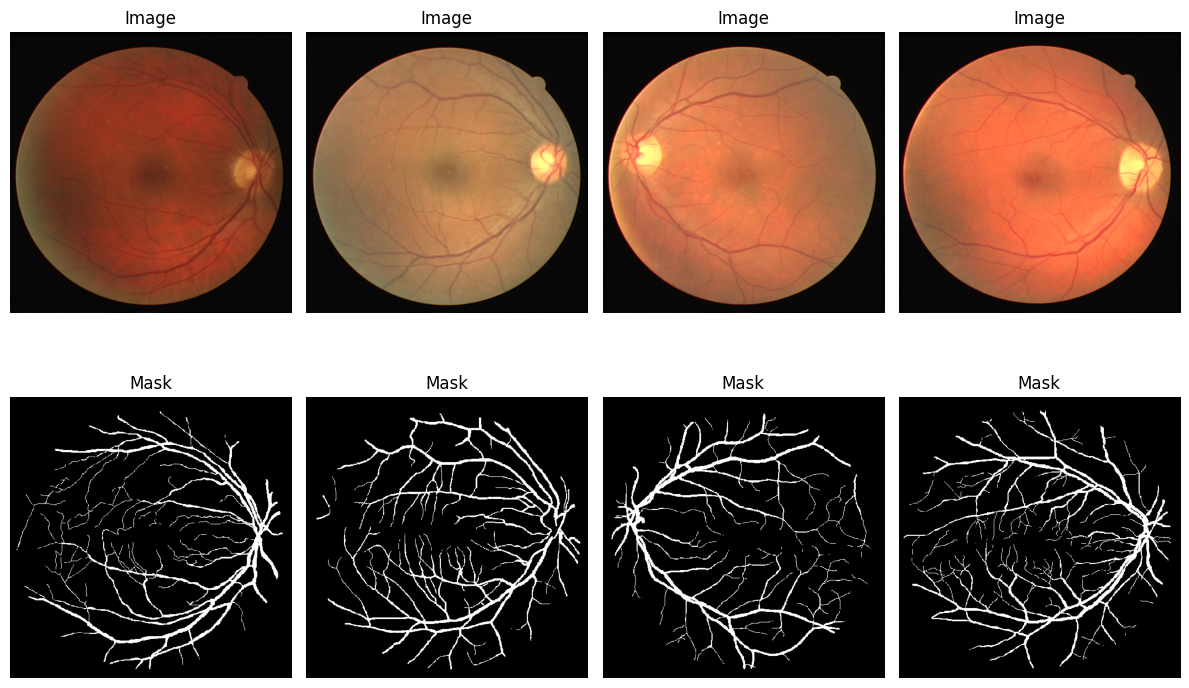

In [7]:
import matplotlib.pyplot as plt

images, masks = next(iter(train_loader))

plt.figure(figsize=(12, 8))

for i in range(4):
    image = images[i].permute(1, 2, 0).numpy()
    mask = masks[i].squeeze().numpy()

    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.title("Image")
    plt.axis("off")

    plt.subplot(2, 4, i + 5)
    plt.imshow(mask, cmap="gray")
    plt.title("Mask")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [8]:
import torch
import torch.nn as nn

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super().__init__()

        self.enc1 = DoubleConv(in_channels, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.enc4 = DoubleConv(256, 512)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.bottleneck = DoubleConv(512, 1024)

        self.up4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(1024, 512)

        self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(128, 64)

        self.final_conv = nn.Conv2d(64, out_channels, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        d4 = torch.cat([d4, e4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.final_conv(d1)

In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = UNet(in_channels=3, out_channels=1).to(device)

sample_input = torch.randn(1, 3, 512, 512).to(device)
sample_output = model(sample_input)

print("Device:", device)
print("Input shape:", sample_input.shape)
print("Output shape:", sample_output.shape)

Device: cuda
Input shape: torch.Size([1, 3, 512, 512])
Output shape: torch.Size([1, 1, 512, 512])


In [10]:
import torch
import torch.nn as nn

class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        probs = probs.view(-1)
        targets = targets.view(-1)

        intersection = (probs * targets).sum()
        dice = (2.0 * intersection + self.smooth) / (probs.sum() + targets.sum() + self.smooth)

        return 1.0 - dice


class BCEDiceLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.dice = DiceLoss()

    def forward(self, logits, targets):
        return self.bce(logits, targets) + self.dice(logits, targets)


def dice_score(logits, targets, threshold=0.5, smooth=1e-6):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()

    preds = preds.view(-1)
    targets = targets.view(-1)

    intersection = (preds * targets).sum()
    dice = (2.0 * intersection + smooth) / (preds.sum() + targets.sum() + smooth)

    return dice.item()


def iou_score(logits, targets, threshold=0.5, smooth=1e-6):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()

    preds = preds.view(-1)
    targets = targets.view(-1)

    intersection = (preds * targets).sum()
    union = preds.sum() + targets.sum() - intersection

    iou = (intersection + smooth) / (union + smooth)

    return iou.item()

In [11]:
criterion = BCEDiceLoss()

images, masks = next(iter(train_loader))
images = images.to(device)
masks = masks.to(device)

model = model.to(device)

with torch.no_grad():
    outputs = model(images)
    loss = criterion(outputs, masks)
    dice = dice_score(outputs, masks)
    iou = iou_score(outputs, masks)

print("Output shape:", outputs.shape)
print("Loss:", loss.item())
print("Dice score:", dice)
print("IoU score:", iou)

Output shape: torch.Size([4, 1, 512, 512])
Loss: 1.633002519607544
Dice score: 0.11767616868019104
IoU score: 0.06251643598079681


In [12]:
from torch.utils.data import DataLoader
import torch.optim as optim
import time

BATCH_SIZE = 2
EPOCHS = 15
LEARNING_RATE = 1e-4

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

model = UNet(in_channels=3, out_channels=1).to(device)
criterion = BCEDiceLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

train_losses = []
val_losses = []
val_dice_scores = []
val_iou_scores = []

def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    epoch_loss = 0.0

    for images, masks in loader:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, masks)

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    return epoch_loss / len(loader)


def validate_one_epoch(model, loader, criterion, device):
    model.eval()
    epoch_loss = 0.0
    epoch_dice = 0.0
    epoch_iou = 0.0

    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)
            loss = criterion(outputs, masks)

            epoch_loss += loss.item()
            epoch_dice += dice_score(outputs, masks)
            epoch_iou += iou_score(outputs, masks)

    return epoch_loss / len(loader), epoch_dice / len(loader), epoch_iou / len(loader)


start_time = time.time()

for epoch in range(EPOCHS):
    train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_dice, val_iou = validate_one_epoch(model, val_loader, criterion, device)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_dice_scores.append(val_dice)
    val_iou_scores.append(val_iou)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Dice: {val_dice:.4f} "
        f"Val IoU: {val_iou:.4f}"
    )

end_time = time.time()

print(f"Training completed in {(end_time - start_time) / 60:.2f} minutes")

Epoch [1/15] Train Loss: 1.2803 Val Loss: 1.4857 Val Dice: 0.0000 Val IoU: 0.0000
Epoch [2/15] Train Loss: 1.1630 Val Loss: 1.4231 Val Dice: 0.0000 Val IoU: 0.0000
Epoch [3/15] Train Loss: 1.0545 Val Loss: 1.3215 Val Dice: 0.0000 Val IoU: 0.0000
Epoch [4/15] Train Loss: 0.9947 Val Loss: 1.2861 Val Dice: 0.0119 Val IoU: 0.0060
Epoch [5/15] Train Loss: 0.9545 Val Loss: 1.2075 Val Dice: 0.1096 Val IoU: 0.0602
Epoch [6/15] Train Loss: 0.9157 Val Loss: 1.1190 Val Dice: 0.2619 Val IoU: 0.1576
Epoch [7/15] Train Loss: 0.8872 Val Loss: 1.0176 Val Dice: 0.4619 Val IoU: 0.3071
Epoch [8/15] Train Loss: 0.8687 Val Loss: 0.9663 Val Dice: 0.5291 Val IoU: 0.3694
Epoch [9/15] Train Loss: 0.8625 Val Loss: 0.9091 Val Dice: 0.6235 Val IoU: 0.4566
Epoch [10/15] Train Loss: 0.8505 Val Loss: 0.9165 Val Dice: 0.5766 Val IoU: 0.4159
Epoch [11/15] Train Loss: 0.8376 Val Loss: 0.8727 Val Dice: 0.6952 Val IoU: 0.5335
Epoch [12/15] Train Loss: 0.8241 Val Loss: 0.8515 Val Dice: 0.6906 Val IoU: 0.5287
Epoch [13/15]

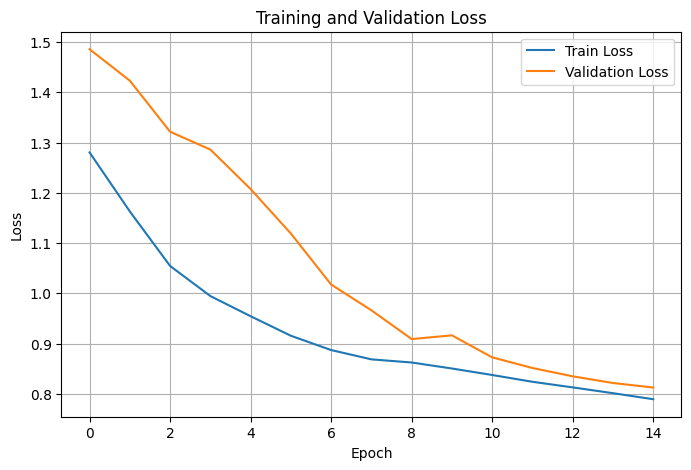

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

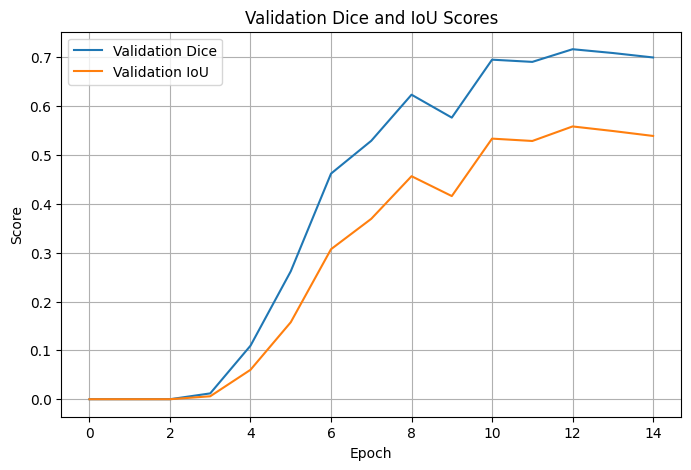

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(val_dice_scores, label="Validation Dice")
plt.plot(val_iou_scores, label="Validation IoU")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Validation Dice and IoU Scores")
plt.legend()
plt.grid(True)
plt.show()

In [16]:
import numpy as np
import torch

thresholds = np.arange(0.1, 0.9, 0.05)

best_threshold = 0
best_dice = 0
threshold_results = []

model.eval()

for threshold in thresholds:
    dice_total = 0
    iou_total = 0

    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)

            dice = dice_score(outputs, masks, threshold=threshold)
            iou = iou_score(outputs, masks, threshold=threshold)

            dice_total += dice
            iou_total += iou

    avg_dice = dice_total / len(val_loader)
    avg_iou = iou_total / len(val_loader)

    threshold_results.append((threshold, avg_dice, avg_iou))

    if avg_dice > best_dice:
        best_dice = avg_dice
        best_threshold = threshold

for threshold, dice, iou in threshold_results:
    print(f"Threshold: {threshold:.2f} | Dice: {dice:.4f} | IoU: {iou:.4f}")

print("\nBest threshold:", round(best_threshold, 2))
print("Best Dice:", round(best_dice, 4))

Threshold: 0.10 | Dice: 0.1593 | IoU: 0.0866
Threshold: 0.15 | Dice: 0.4040 | IoU: 0.2545
Threshold: 0.20 | Dice: 0.6193 | IoU: 0.4493
Threshold: 0.25 | Dice: 0.6781 | IoU: 0.5130
Threshold: 0.30 | Dice: 0.6946 | IoU: 0.5321
Threshold: 0.35 | Dice: 0.7006 | IoU: 0.5393
Threshold: 0.40 | Dice: 0.7027 | IoU: 0.5421
Threshold: 0.45 | Dice: 0.7017 | IoU: 0.5411
Threshold: 0.50 | Dice: 0.6997 | IoU: 0.5390
Threshold: 0.55 | Dice: 0.6964 | IoU: 0.5355
Threshold: 0.60 | Dice: 0.6908 | IoU: 0.5293
Threshold: 0.65 | Dice: 0.6839 | IoU: 0.5217
Threshold: 0.70 | Dice: 0.6741 | IoU: 0.5108
Threshold: 0.75 | Dice: 0.6605 | IoU: 0.4961
Threshold: 0.80 | Dice: 0.6416 | IoU: 0.4759
Threshold: 0.85 | Dice: 0.6138 | IoU: 0.4469

Best threshold: 0.4
Best Dice: 0.7027


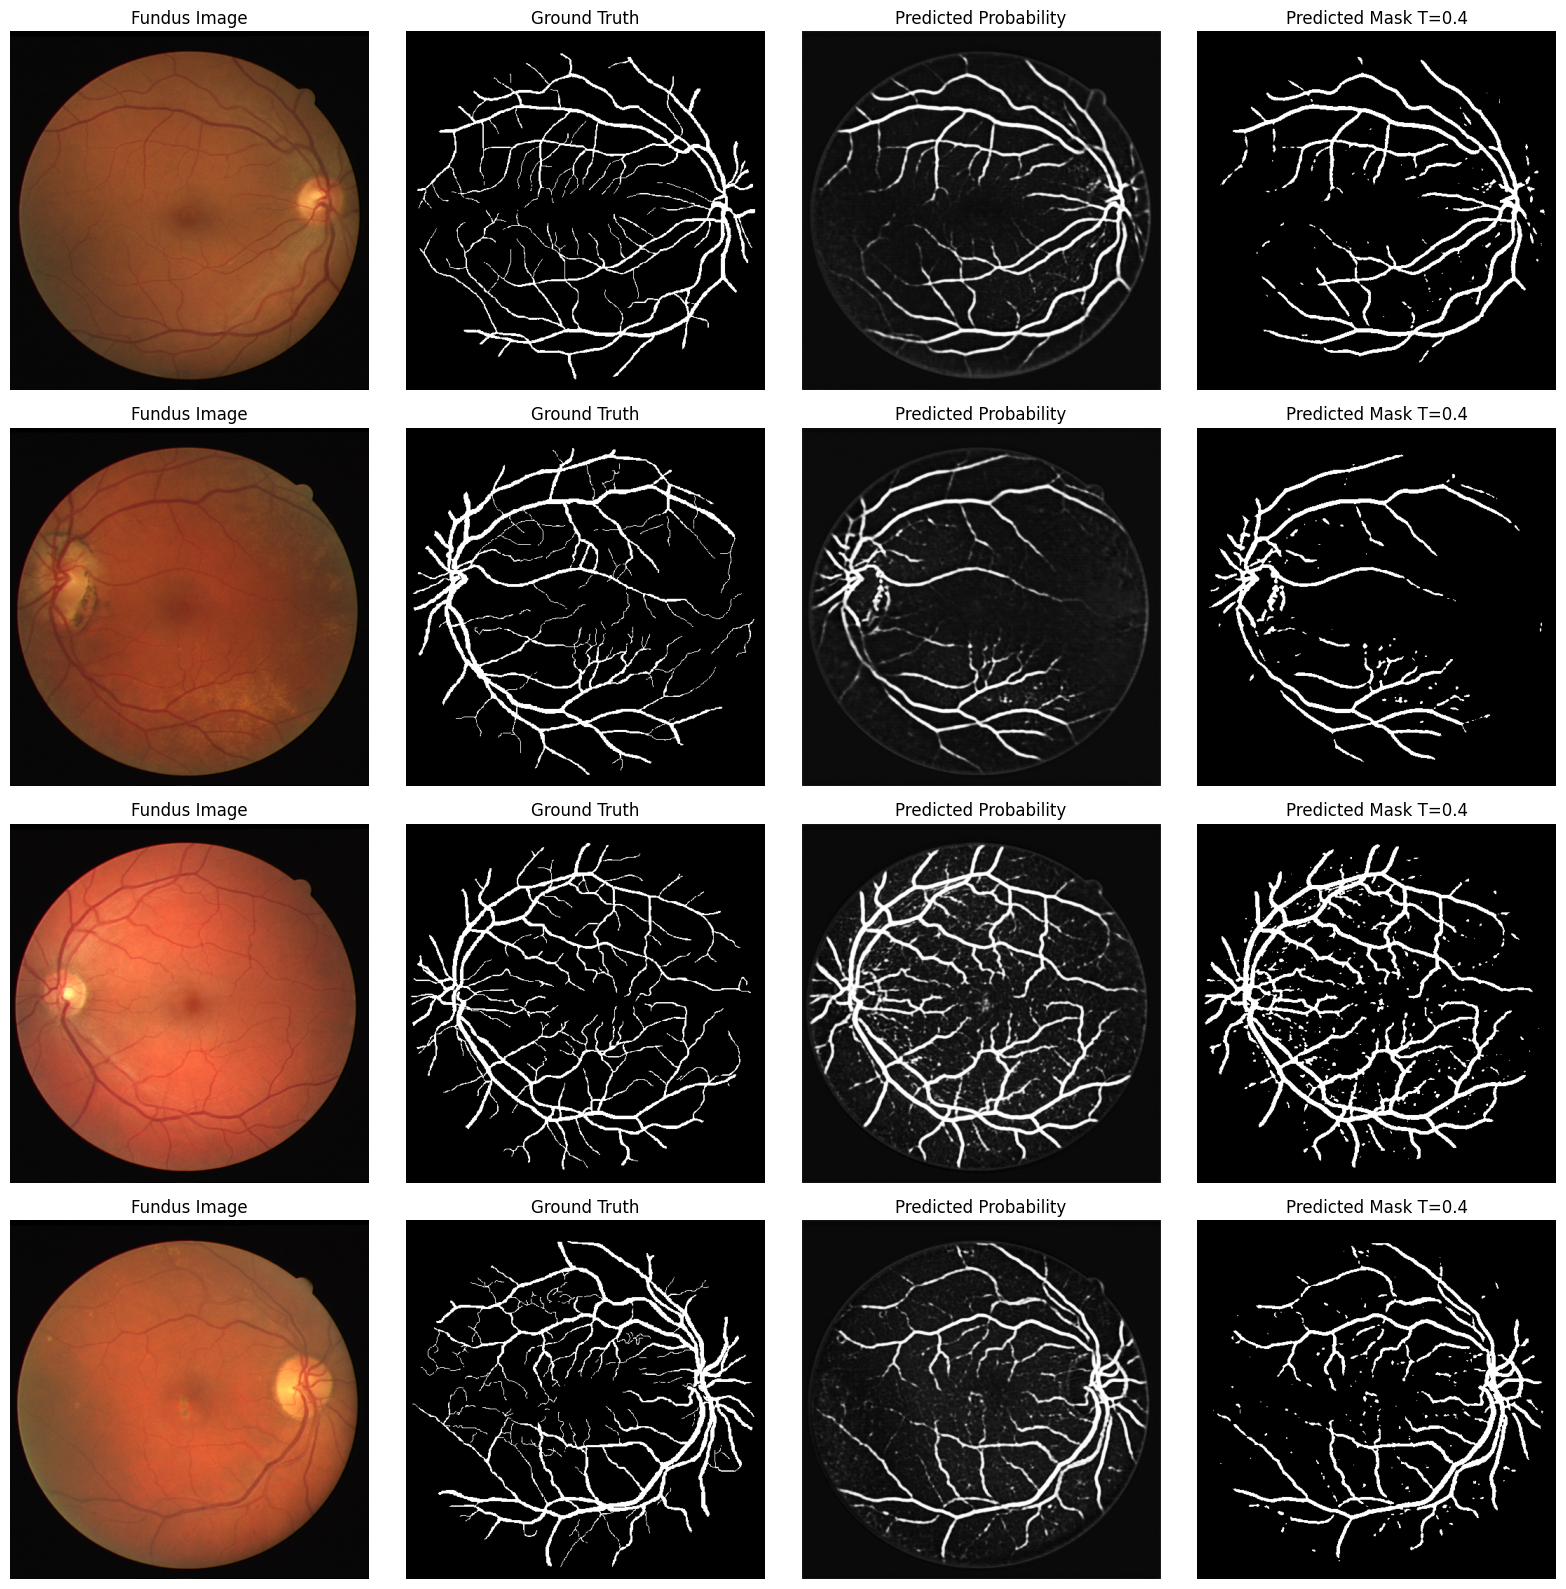

In [17]:
BEST_THRESHOLD = 0.40

val_vis_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=2)

model.eval()

images, masks = next(iter(val_vis_loader))
images = images.to(device)
masks = masks.to(device)

with torch.no_grad():
    outputs = model(images)
    probs = torch.sigmoid(outputs)
    preds = (probs > BEST_THRESHOLD).float()

images_cpu = images.cpu()
masks_cpu = masks.cpu()
probs_cpu = probs.cpu()
preds_cpu = preds.cpu()

num_samples = min(4, images_cpu.shape[0])

plt.figure(figsize=(16, 4 * num_samples))

for i in range(num_samples):
    image = images_cpu[i].permute(1, 2, 0).numpy()
    gt_mask = masks_cpu[i].squeeze().numpy()
    prob_mask = probs_cpu[i].squeeze().numpy()
    pred_mask = preds_cpu[i].squeeze().numpy()

    plt.subplot(num_samples, 4, i * 4 + 1)
    plt.imshow(image)
    plt.title("Fundus Image")
    plt.axis("off")

    plt.subplot(num_samples, 4, i * 4 + 2)
    plt.imshow(gt_mask, cmap="gray")
    plt.title("Ground Truth")
    plt.axis("off")

    plt.subplot(num_samples, 4, i * 4 + 3)
    plt.imshow(prob_mask, cmap="gray")
    plt.title("Predicted Probability")
    plt.axis("off")

    plt.subplot(num_samples, 4, i * 4 + 4)
    plt.imshow(pred_mask, cmap="gray")
    plt.title(f"Predicted Mask T={BEST_THRESHOLD}")
    plt.axis("off")

plt.tight_layout()
plt.show()

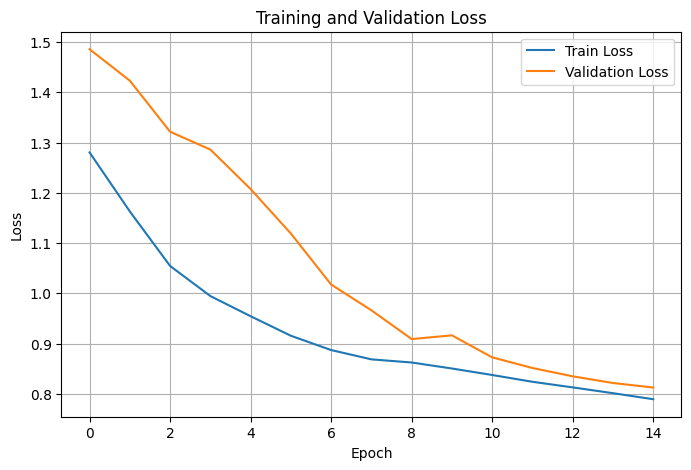

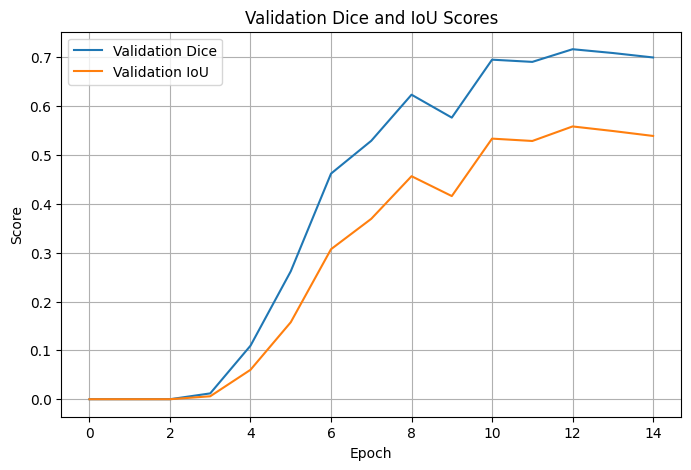

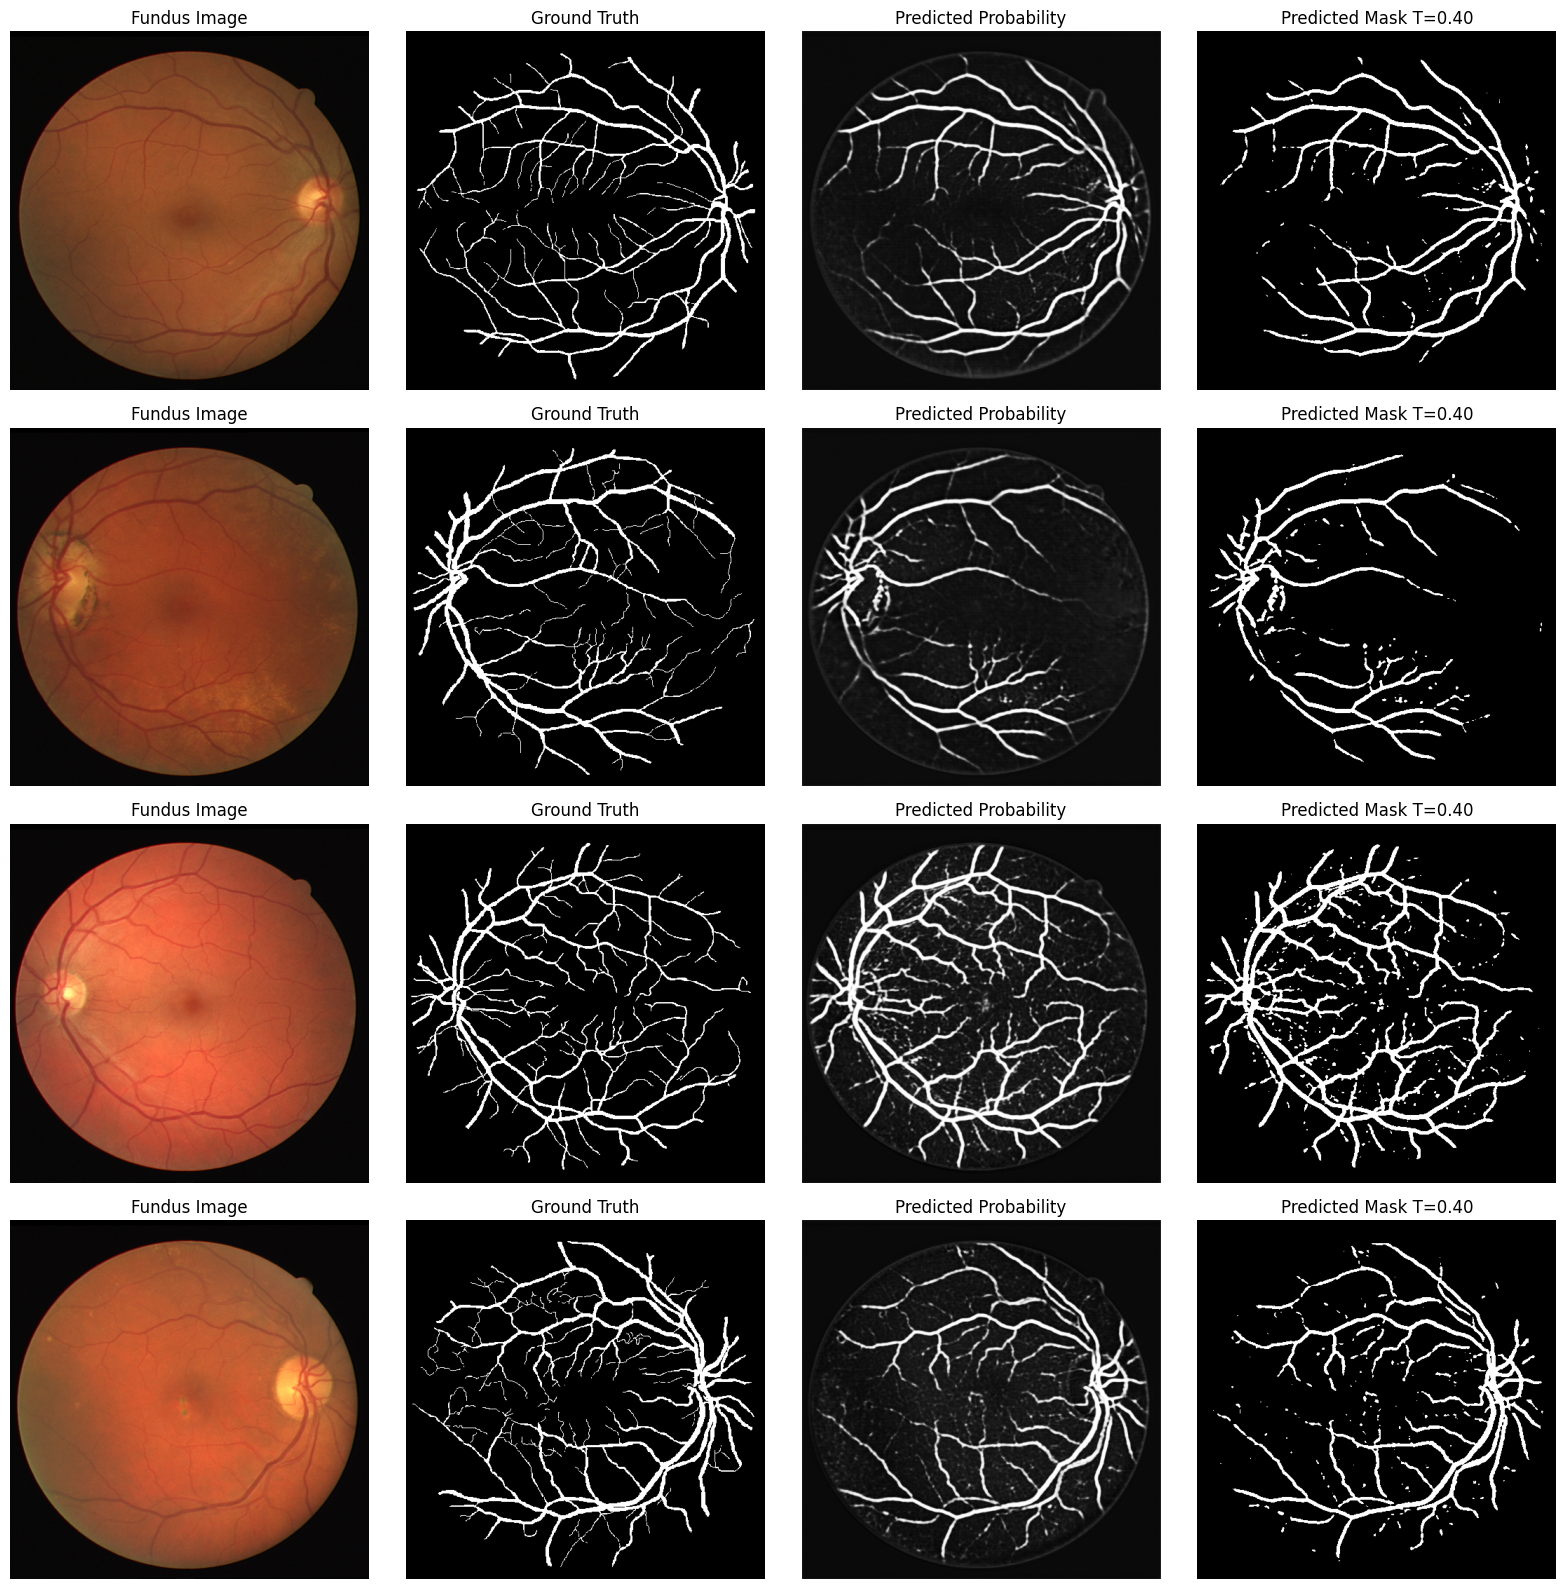

Saved model: /content/retinal-vessel-segmentation-unet/models/unet_retinal_vessel_segmentation.pth
Saved metrics: /content/retinal-vessel-segmentation-unet/results/metrics.json
Saved loss curve: /content/retinal-vessel-segmentation-unet/results/training_validation_loss.png
Saved metric curve: /content/retinal-vessel-segmentation-unet/results/validation_dice_iou.png
Saved predictions: /content/retinal-vessel-segmentation-unet/results/sample_predictions/sample_predictions.png


In [18]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import torch

results_dir = project_dir / "results"
sample_dir = results_dir / "sample_predictions"
model_dir = project_dir / "models"

results_dir.mkdir(parents=True, exist_ok=True)
sample_dir.mkdir(parents=True, exist_ok=True)
model_dir.mkdir(parents=True, exist_ok=True)

torch.save(model.state_dict(), model_dir / "unet_retinal_vessel_segmentation.pth")

metrics = {
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "image_size": IMG_SIZE,
    "best_threshold": float(best_threshold),
    "best_validation_dice": float(best_dice),
    "final_validation_dice": float(val_dice_scores[-1]),
    "final_validation_iou": float(val_iou_scores[-1]),
    "final_training_loss": float(train_losses[-1]),
    "final_validation_loss": float(val_losses[-1])
}

with open(results_dir / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.savefig(results_dir / "training_validation_loss.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(val_dice_scores, label="Validation Dice")
plt.plot(val_iou_scores, label="Validation IoU")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Validation Dice and IoU Scores")
plt.legend()
plt.grid(True)
plt.savefig(results_dir / "validation_dice_iou.png", dpi=300, bbox_inches="tight")
plt.show()

BEST_THRESHOLD = float(best_threshold)

val_vis_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=2)

model.eval()

images, masks = next(iter(val_vis_loader))
images = images.to(device)
masks = masks.to(device)

with torch.no_grad():
    outputs = model(images)
    probs = torch.sigmoid(outputs)
    preds = (probs > BEST_THRESHOLD).float()

images_cpu = images.cpu()
masks_cpu = masks.cpu()
probs_cpu = probs.cpu()
preds_cpu = preds.cpu()

num_samples = min(4, images_cpu.shape[0])

plt.figure(figsize=(16, 4 * num_samples))

for i in range(num_samples):
    image = images_cpu[i].permute(1, 2, 0).numpy()
    gt_mask = masks_cpu[i].squeeze().numpy()
    prob_mask = probs_cpu[i].squeeze().numpy()
    pred_mask = preds_cpu[i].squeeze().numpy()

    plt.subplot(num_samples, 4, i * 4 + 1)
    plt.imshow(image)
    plt.title("Fundus Image")
    plt.axis("off")

    plt.subplot(num_samples, 4, i * 4 + 2)
    plt.imshow(gt_mask, cmap="gray")
    plt.title("Ground Truth")
    plt.axis("off")

    plt.subplot(num_samples, 4, i * 4 + 3)
    plt.imshow(prob_mask, cmap="gray")
    plt.title("Predicted Probability")
    plt.axis("off")

    plt.subplot(num_samples, 4, i * 4 + 4)
    plt.imshow(pred_mask, cmap="gray")
    plt.title(f"Predicted Mask T={BEST_THRESHOLD:.2f}")
    plt.axis("off")

plt.tight_layout()
plt.savefig(sample_dir / "sample_predictions.png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved model:", model_dir / "unet_retinal_vessel_segmentation.pth")
print("Saved metrics:", results_dir / "metrics.json")
print("Saved loss curve:", results_dir / "training_validation_loss.png")
print("Saved metric curve:", results_dir / "validation_dice_iou.png")
print("Saved predictions:", sample_dir / "sample_predictions.png")